# Inspect saved Group 5 results
CPU only. This notebook reads recorded metrics and does not run a model.

In [1]:
from pathlib import Path
import json, subprocess, sys
ROOT=Path.cwd()
if not (ROOT/'results/raw').is_dir(): ROOT=ROOT.parent
assert (ROOT/'results/raw').is_dir()
subprocess.run([sys.executable,str(ROOT/'scripts/validate_results.py')],cwd=ROOT,check=True)


CompletedProcess(args=['C:\\Users\\ACER\\Downloads\\DPR-main\\DPR-main\\.venv-dpr\\Scripts\\python.exe', 'C:\\Users\\ACER\\Downloads\\DPR-main\\DPR-main\\outputs\\github\\dpr-50k-reader-reranking\\scripts\\validate_results.py'], returncode=0)

In [2]:
for dataset in ['nq','curatedtrec','trivia']:
    before=json.loads((ROOT/'results/raw/dpr_multi.json').read_text())['test_results'][dataset+'_test']
    after=json.loads((ROOT/'results/raw'/f'{dataset}_reader200.json').read_text())['test_results'][dataset+'_test']
    print(dataset,'n=',before['questions'])
    for k in ['1','5','20','100']:
        b=100*before['hits'][k]/before['questions'];a=100*after['hits'][k]/after['questions']
        print(f'  Hit@{k}: {b:.2f}% -> {a:.2f}%; delta={a-b:+.2f} percentage points')


nq n= 3610
  Hit@1: 6.18% -> 7.09%; delta=+0.91 percentage points
  Hit@5: 14.96% -> 15.93%; delta=+0.97 percentage points
  Hit@20: 25.68% -> 27.34%; delta=+1.66 percentage points
  Hit@100: 37.34% -> 39.17%; delta=+1.83 percentage points
curatedtrec n= 694
  Hit@1: 4.90% -> 9.22%; delta=+4.32 percentage points
  Hit@5: 11.82% -> 14.12%; delta=+2.31 percentage points
  Hit@20: 16.86% -> 18.59%; delta=+1.73 percentage points
  Hit@100: 24.06% -> 24.06%; delta=+0.00 percentage points
trivia n= 11313
  Hit@1: 9.81% -> 18.46%; delta=+8.64 percentage points
  Hit@5: 20.77% -> 31.32%; delta=+10.55 percentage points
  Hit@20: 33.60% -> 42.64%; delta=+9.04 percentage points
  Hit@100: 48.04% -> 51.57%; delta=+3.53 percentage points


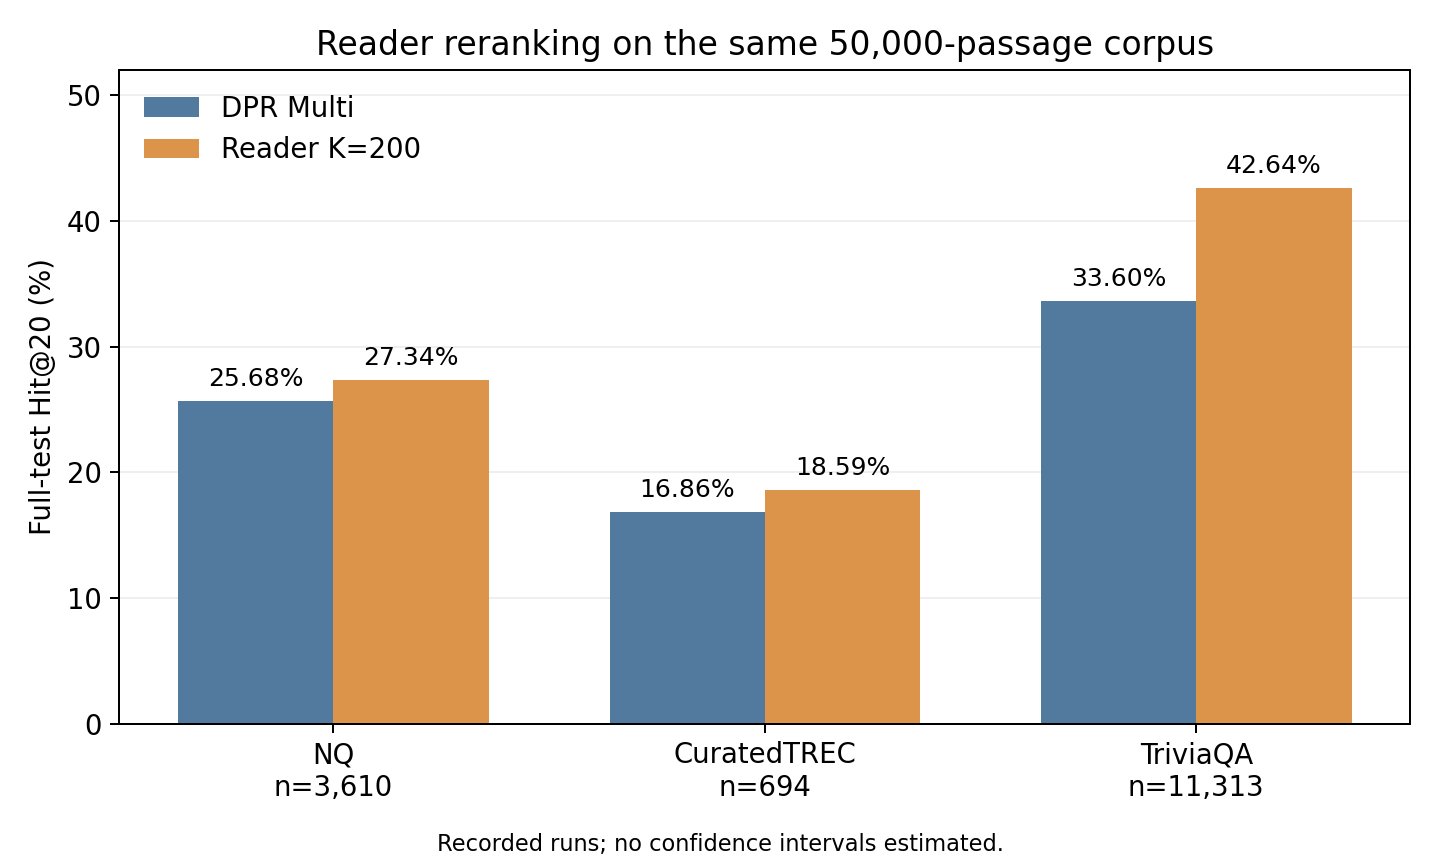

In [3]:
from IPython.display import Image, display
display(Image(filename=str(ROOT/'images/hit_at_20.png')))
